# Hypothesis Tests

## Introduction

## Tests about the Mean of a Normal Distribution

In [44]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(321)

n = 80
mu = 150
sigma = 15

mu_0 = 135

single_group = np.random.normal(loc=mu, scale=sigma, size=n)
single_group

array([152.58779203, 174.53223798, 150.56004604, 136.73775472,
       132.85211616, 140.6795094 , 129.77025626, 137.70403448,
       147.98619151, 173.99400065, 145.74594549, 142.40490274,
       151.03362636, 171.78389257, 125.41356589, 145.31010838,
       136.93100359, 143.14976405, 148.16299914, 143.2340654 ,
       133.61574395, 129.56730484, 147.51019546, 159.68083629,
       162.22610282, 149.7216046 , 156.50071016, 155.6225485 ,
       136.66408528, 156.18411382, 134.54514207, 144.8819786 ,
       119.34319993, 138.93542827, 170.37450656, 145.47150888,
       143.51990922, 147.92243754, 155.46272705, 165.47207475,
       161.64922462, 148.0855994 , 151.46833786, 126.50503744,
       144.56816859, 153.19306331, 153.98901964, 129.03999286,
       152.99228644, 146.53599693, 152.05253107, 177.72515515,
       165.96675366, 126.93883846, 151.1169039 , 169.37755638,
       164.49958697, 156.3292526 , 176.93676368, 147.30672926,
       164.73663851, 161.04570509, 136.92007969, 154.84

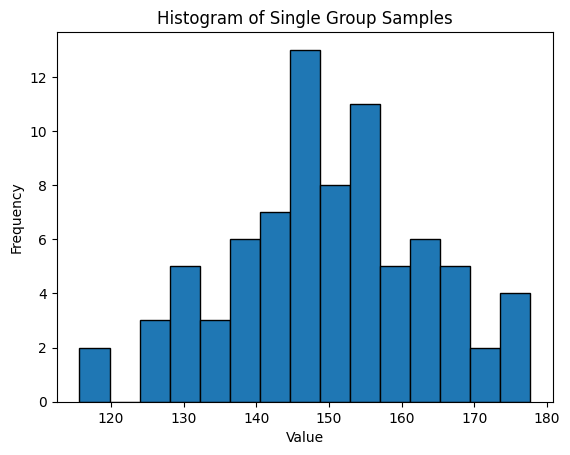

In [45]:
plt.hist(single_group, bins=15, edgecolor='black')
plt.title('Histogram of Single Group Samples')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.show()

In [46]:
single_group_sim_sigma1 = np.random.normal(loc=mu, scale=sigma, size=(1000, n))
single_group_sim_mean_sigma1 = np.mean(single_group_sim_sigma1, axis=1)

single_group_sim_sigma2 = np.random.normal(loc=mu, scale=sigma*3, size=(1000, n))
single_group_sim_mean_sigma2 = np.mean(single_group_sim_sigma2, axis=1)


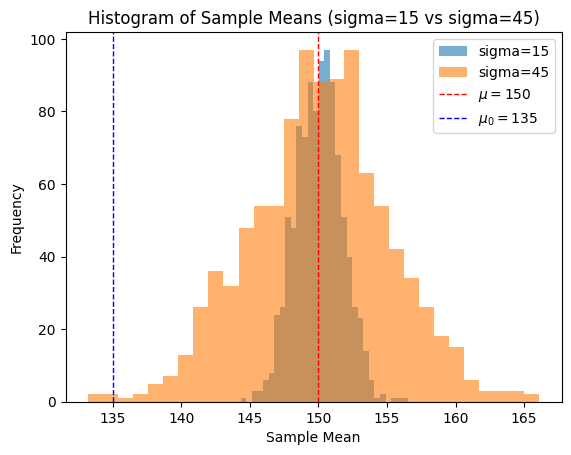

In [47]:
plt.hist(single_group_sim_mean_sigma1, bins=30, alpha=0.6, label='sigma=15')
plt.hist(single_group_sim_mean_sigma2, bins=30, alpha=0.6, label='sigma=45')
plt.axvline(mu, color='red', linestyle='dashed', linewidth=1, label=rf'$\mu = {mu}$')
plt.axvline(mu_0, color='blue', linestyle='dashed', linewidth=1, label=rf'$\mu_0 = {mu_0}$')
plt.xlabel('Sample Mean')
plt.ylabel('Frequency')
plt.title('Histogram of Sample Means (sigma=15 vs sigma=45)')
plt.legend()
plt.show()

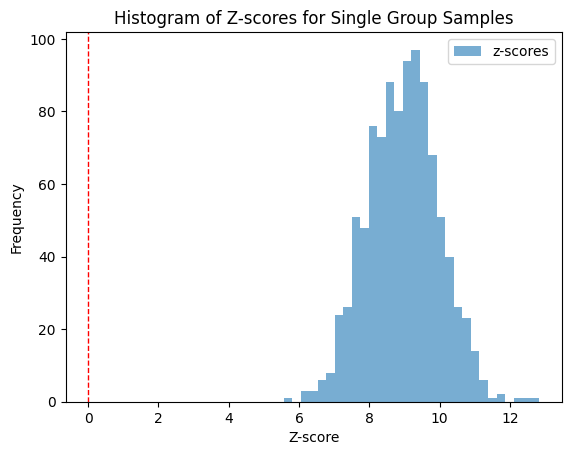

In [48]:
z_scores = (single_group_sim_mean_sigma1 - mu_0) / (sigma / np.sqrt(n))

plt.hist(z_scores, bins=30, alpha=0.6, label='z-scores')
plt.axvline(0, color='red', linestyle='dashed', linewidth=1)
plt.xlabel('Z-score')
plt.ylabel('Frequency')
plt.title('Histogram of Z-scores for Single Group Samples')
plt.legend()
plt.show()

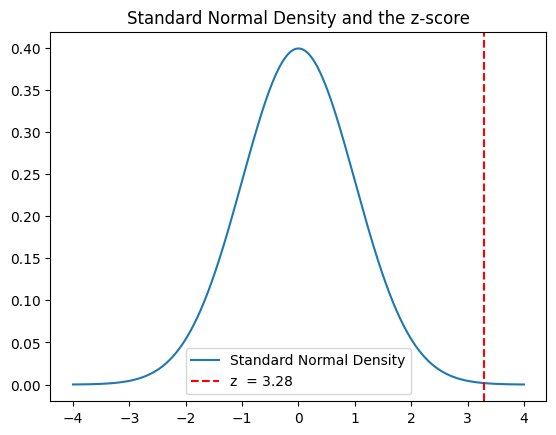

In [43]:
# Plot the standard normal density and the empirical mean of z_values_nominator
from scipy import stats

x = np.linspace(-4, 4, 1000)
y = stats.norm.pdf(x)

z = (np.mean(single_group) - mu_0) / (sigma / np.sqrt(n))

plt.plot(x, y, label='Standard Normal Density')
plt.axvline(z, color='red', linestyle='--', label=f'z  = {z:.2f}')
plt.title('Standard Normal Density and the z-score')
plt.legend()
plt.show()

In [7]:
# Compute the critical z-value for a significance level of 0.05

stats.norm.ppf(0.05)

np.float64(-1.6448536269514729)

In [8]:
# Compute the p-value of the test

prob_less_than_z = stats.norm.cdf(z)
prob_less_than_z

np.float64(1.0)

## Testing a Hypothesis about a Single Proportion

In [9]:
from scipy import stats
import numpy as np

n = 100
p = 0.7
p_hat = 0.6

expected_successes = p * n
observed_successes = p_hat * n

print("Probability of seeing less or equal to 60 successes out of 100 trials:", stats.binom.cdf(observed_successes, n, p))

Probability of seeing less or equal to 60 successes out of 100 trials: 0.020988576003924803


In [10]:
## Generate a sample of 1000 binomial random variables, each showing the number of successes in 100 trials

sample100 = np.random.binomial(n, p, size = 10000)

# Print the first 20 samples
print(sample100[0:20])
print("Mean of the samples:", np.mean(sample100))

# Now we can count the number of samples with less or equal to 60 successes

print("Number of samples with less or equal to 60 successes:", np.sum(sample100 <= 60))

[64 63 71 64 78 69 71 65 68 62 61 76 68 71 72 75 75 68 68 69]
Mean of the samples: 70.0336
Number of samples with less or equal to 60 successes: 195


In [11]:
1000 * 0.0209885760

20.988576

## Confidence Interval for the Population Proportion

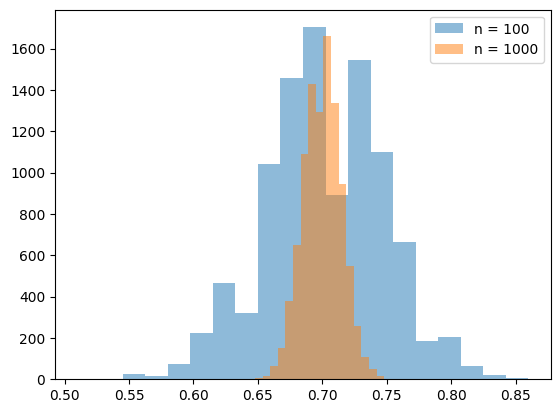

In [12]:
# Visualize the distribution of the samples

import matplotlib.pyplot as plt

n1000 = 1000
sample1000 = np.random.binomial(n1000, p, size = 10000)

# Create two histograms for the two samples

plt.hist(sample100 / n, bins = 20, alpha = 0.5, label = "n = 100")
plt.hist(sample1000 / n1000, bins = 20, alpha = 0.5, label = "n = 1000")
plt.legend(loc = "upper right")
plt.show()

In [13]:
# Central 95% interval for the population proportion of successes

# Calculate the 0.025 and 0.975 quantiles of the distribution of the samples

q_025 = np.quantile(sample100 / n, 0.025)
q_975 = np.quantile(sample100 / n, 0.975)

print("Central 95% interval for the population proportion of successes:", q_025, q_975)

# About 95 percent of the samples have a proportion of successes between 0.61 and 0.79

np.mean((sample100 / n > q_025) & (sample100 / n < q_975))

Central 95% interval for the population proportion of successes: 0.61 0.79


np.float64(0.9372)

In [14]:
# The 0.025 and 0.975 quantiles of the standard normal distribution

qn_025 = stats.norm.ppf(0.025)
qn_975 = stats.norm.ppf(0.975)

print("0.025 and 0.975 quantiles of the standard normal distribution:", qn_025, qn_975)

0.025 and 0.975 quantiles of the standard normal distribution: -1.9599639845400545 1.959963984540054


## Quantiles of the Standard Normal Distribution

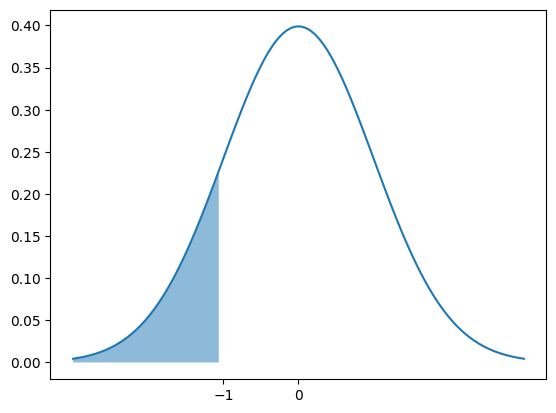

In [15]:
# Plot the standard normal distribution and the probability of events less than -1

x = np.linspace(-3, 3, 100)
y = stats.norm.pdf(x)
plt.plot(x, y)
plt.fill_between(x, y, where = x < -1, alpha = 0.5)
plt.xticks([-1, 0])
plt.show()


In [16]:
# Calculate the probability of observing less than -1 from a standard normal distribution

print("Probability of observing less than -1 from a standard normal distribution:", stats.norm.cdf(-1))


Probability of observing less than -1 from a standard normal distribution: 0.15865525393145707


In [17]:
print("The 0.025 quantile of the standard normal distribution", stats.norm.ppf(0.025))
print("The probability of observing less than the 0.025 quantile of a standard normal distribution", stats.norm.cdf(stats.norm.ppf(0.025)))

The 0.025 quantile of the standard normal distribution -1.9599639845400545
The probability of observing less than the 0.025 quantile of a standard normal distribution 0.024999999999999977


([<matplotlib.axis.XTick at 0x7e578f0c6d50>,
 [Text(-1.9599639845400545, 0, '-1.96'), Text(0.0, 0, '0')])

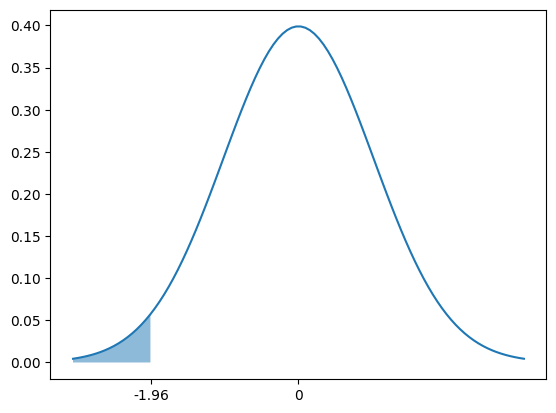

In [18]:
# Plot the normal distribution and the probability of events less than the 0.025 quantile

x = np.linspace(-3, 3, 100)
y = stats.norm.pdf(x)
plt.plot(x, y)
plt.fill_between(x, y, where = x < stats.norm.ppf(0.025), alpha = 0.5)
plt.xticks([stats.norm.ppf(0.025), 0], [stats.norm.ppf(0.025).round(2), 0])



In [19]:
# Calculate the probability of observing less than the 0.975 quantile from a standard normal distribution

print("The 0.975 quantile of the standard normal distribution", stats.norm.ppf(0.975))
print("Probability of observing less than the 0.975 quantile from a standard normal distribution:", stats.norm.cdf(stats.norm.ppf(0.975)))


The 0.975 quantile of the standard normal distribution 1.959963984540054
Probability of observing less than the 0.975 quantile from a standard normal distribution: 0.975


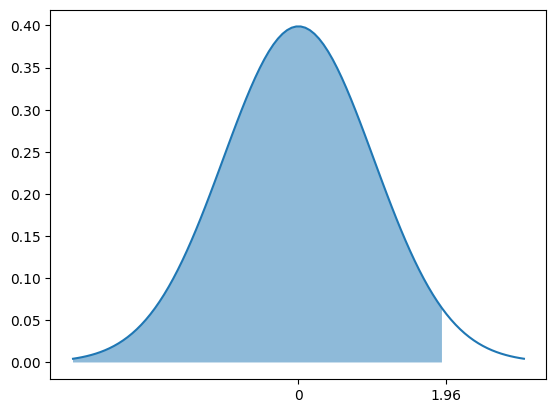

In [20]:
# Plot the normal distribution and the probability of events less than the 0.975 quantile

x = np.linspace(-3, 3, 100)
y = stats.norm.pdf(x)
plt.plot(x, y)
plt.fill_between(x, y, where = x < stats.norm.ppf(0.975), alpha = 0.5)
plt.xticks([0, stats.norm.ppf(0.975)], [0, stats.norm.ppf(0.975).round(2)])
plt.show()


([<matplotlib.axis.XTick at 0x7e578efc42d0>,
 [Text(-1.9599639845400545, 0, '-1.96'), Text(1.959963984540054, 0, '1.96')])

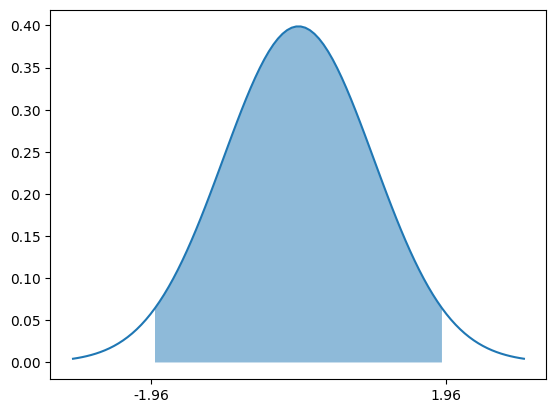

In [21]:
# Plot the normal distribution and the probability of events between the 0.025 and 0.975 quantiles
# Set the axis breaks to the quantiles

x = np.linspace(-3, 3, 100)
y = stats.norm.pdf(x)
plt.plot(x, y)
plt.fill_between(x, y, where = (x > stats.norm.ppf(0.025)) & (x < stats.norm.ppf(0.975)), alpha = 0.5)
plt.xticks([stats.norm.ppf(0.025), stats.norm.ppf(0.975)], [stats.norm.ppf(0.025).round(2), stats.norm.ppf(0.975).round(2)])


In [22]:
print("Lower CI bound", 0.6 - 1.96 * np.sqrt(0.6 * 0.4 / 100))
print("Upper CI bound", 0.6 + 1.96 * np.sqrt(0.6 * 0.4 / 100))


Lower CI bound 0.5039800020828994
Upper CI bound 0.6960199979171006


Standard error of the sample proportion of successes: [0.0144496  0.01462532 0.01488083 ... 0.01463827 0.01465114 0.01434922]


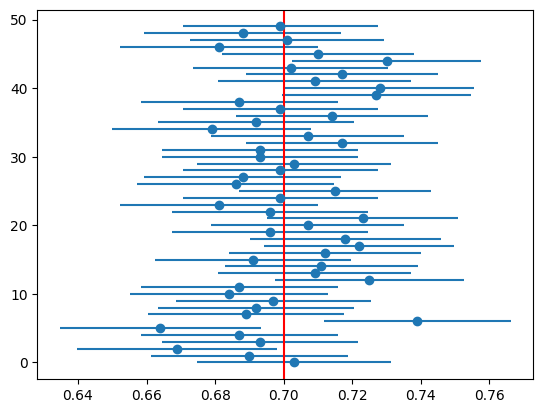

In [23]:
# Compute the confidence intervals for the population proportion of successes

p_hat = sample1000 / n1000
se = np.sqrt(p_hat * (1 - p_hat) / n1000)

print("Standard error of the sample proportion of successes:", se)
ci_025 = p_hat - qn_975 * se
ci_975 = p_hat - qn_025 * se
# Plot the confidence intervals

# Plot the confidence intervals and the population proportion of successes for the first 50 samples
# with the sample number on the y-axis

show_samples = 50


plt.errorbar(p_hat[0:show_samples], range(show_samples), xerr = qn_975 * se[0:show_samples], fmt = "o")
plt.axvline(p, color = "red")
plt.show()

In [24]:
print("Number of confidence intervals that contain the population proportion of successes:", np.sum((ci_025 < p) & (ci_975 > p)))
print("Proportion of confidence intervals that contain the population proportion of successes:", np.mean((ci_025 < p) & (ci_975 > p)))

Number of confidence intervals that contain the population proportion of successes: 9520
Proportion of confidence intervals that contain the population proportion of successes: 0.952


# Comparing the Simulated Distribution and the Normal Approximation

In [25]:
# Plot the quantile 

## Comparing Two Proportions (Optional)

In [26]:
p1 = 0.5
p2 = 0.7

n = 100

sample1 = np.random.binomial(n, p1, size = 1)
sample2 = np.random.binomial(n, p2, size = 1)

# Perform a z-test for the difference of two population proportions

p_hat1 = sample1 / n
p_hat2 = sample2 / n

pooled_sample = sample1 + sample2
pooled_n = 2 * n

p_hat_pooled = pooled_sample / pooled_n

se_pooled = np.sqrt(p_hat_pooled * (1 - p_hat_pooled) * (1 / n + 1 / n))

z = (p_hat1 - p_hat2) / se_pooled

p_value = 2 * stats.norm.cdf(-np.abs(z))

print("p-value for the difference of two population proportions:", p_value)

p-value for the difference of two population proportions: [1.79856929e-07]


# On the Use of the Normal Approximation (Optional)

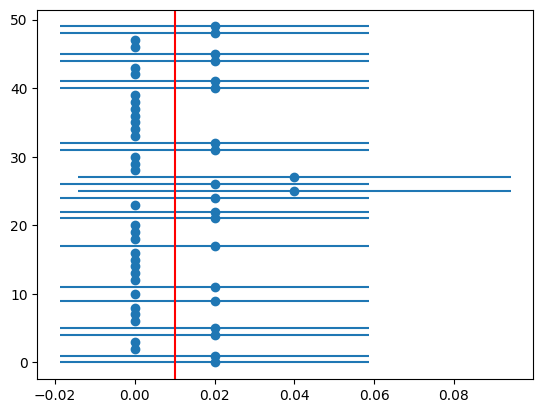

In [27]:
# The distribution of the sample proportion with a very skewed population proportion

p = 0.01
n = 50

sample1000_skewed = np.random.binomial(n, p, size = 10000)

p_hat_skewed = sample1000_skewed / n

se_skewed = np.sqrt(p_hat_skewed * (1 - p_hat_skewed) / n)

ci_025_skewed = p_hat_skewed - qn_975 * se_skewed
ci_975_skewed = p_hat_skewed - qn_025 * se_skewed

# Plot the confidence intervals and the population proportion of successes for the first 50 samples

plt.errorbar(p_hat_skewed[0:show_samples], range(show_samples), xerr = qn_975 * se_skewed[0:show_samples], fmt = "o")
plt.axvline(p, color = "red")
plt.show()


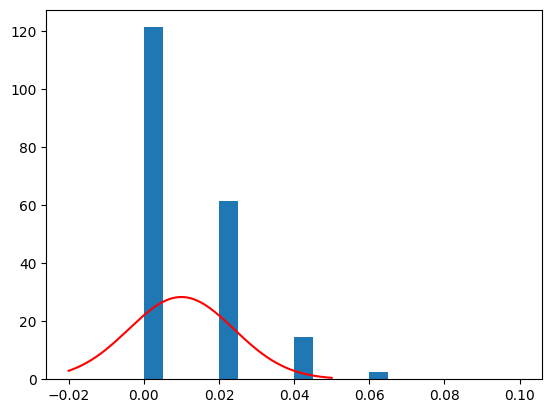

In [28]:
# Plot the distribution of the sample proportion of successes
# and overlay the normal approximation

plt.hist(p_hat_skewed, bins = 20, density=True)
x = np.linspace(-0.02, 0.05, 1000)
y = stats.norm.pdf(x, p, np.sqrt(p * (1 - p) / n))
plt.plot(x, y, color = "red")
plt.show()

## Tests for the Mean (Optional)

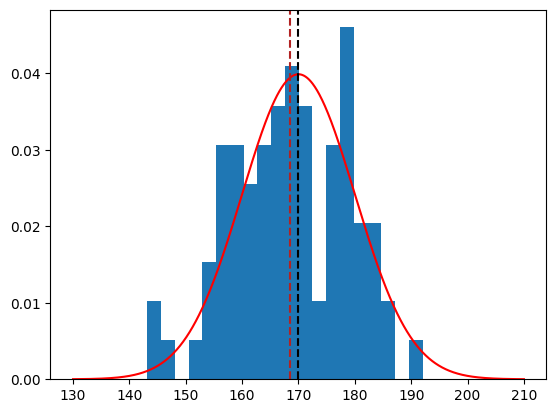

In [29]:
import matplotlib.pyplot as plt

# Simulate 80 draws from a normal distribution with mean 170 and standard deviation 10

n = 80
mu = 170
sigma = 10

sample100 = np.random.normal(mu, sigma, n)

# Plot the histogram of the sample and overlay the density of the normal distribution

plt.hist(sample100, bins = 20, density = True)
x = np.linspace(130, 210, 1000)
y = stats.norm.pdf(x, mu, sigma)
plt.plot(x, y, 'r')
plt.axvline(x = mu, color = 'black', linestyle = '--')
plt.axvline(x = sample100.mean(), color = 'firebrick', linestyle = '--')
plt.show()


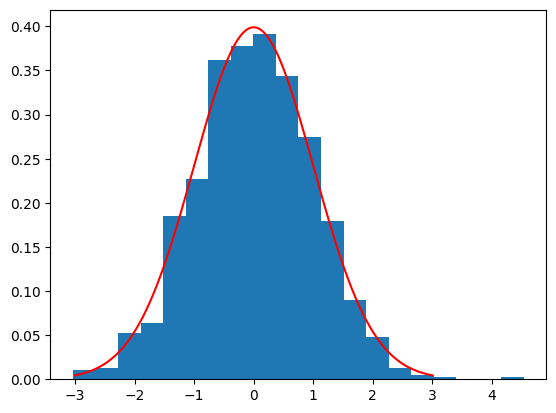

In [30]:
# Simulate 1000 samples of size 80 from a normal distribution with mean 170 and standard deviation 10

n = 80
mu = 170
sigma = 10
R = 1000

samples = np.random.normal(mu, sigma, (R, n))

# Calculate the z-statistic for each sample

z = (samples.mean(axis = 1) - mu) / (sigma / np.sqrt(n))

# Plot the histogram of the z-statistics and overlay the density of the standard normal distribution

plt.hist(z, bins = 20, density = True)
x = np.linspace(-3, 3, 1000)
y = stats.norm.pdf(x, 0, 1)
plt.plot(x, y, 'r')
plt.show()



In [31]:
# z-statistic for the sample

z = (sample100.mean() - mu) / (sigma / np.sqrt(n))
print("z-statistic for the sample:", z)

# p-value for the z-statistic

p_value = stats.norm.cdf(z)
p_value

z-statistic for the sample: -1.3590741548084249


np.float64(0.08706154585365888)

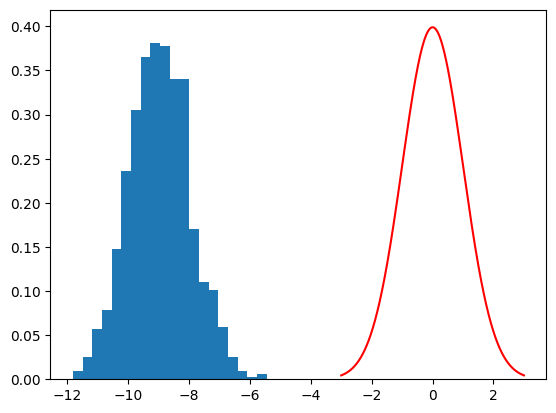

In [32]:
# Generate 1000 samples of size 80 from a normal distribution with mean 160 (a value from the alternative) and standard deviation 10

n = 80
mu = 160
sigma = 10
R = 1000

samples = np.random.normal(mu, sigma, (R, n))

# Calculate the z-statistic for each sample

z = (samples.mean(axis = 1) - 170) / (sigma / np.sqrt(n))


# Plot the histogram of the z-statistics and overlay the density of the standard normal distribution

plt.hist(z, bins = 20, density = True)
x = np.linspace(-3, 3, 1000)
y = stats.norm.pdf(x, 0, 1)
plt.plot(x, y, 'r')
plt.show()



In [33]:
# Take a single sample of size 80 from a normal distribution with mean 160 and standard deviation 10, 
# calculate the z-statistic and compute its p-value

sample100 = np.random.normal(160, 10, n)

z = (sample100.mean() - 170) / (sigma / np.sqrt(n))

p_value = stats.norm.cdf(z)
p_value

np.float64(6.9277074642664895e-22)

## Some Notes about the p-value (Optional)

Number of p-values less than 0.05: 55
Proportion of p-values less than 0.05: 0.055


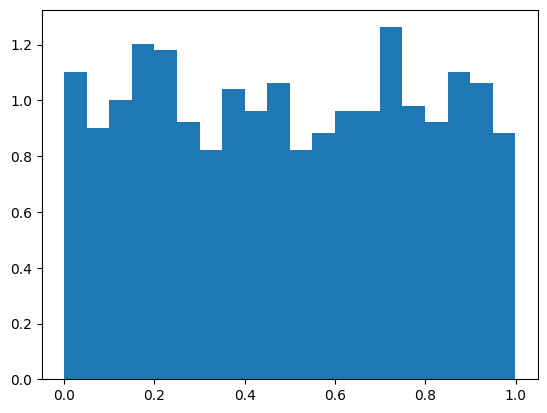

In [34]:
# Generate 1000 samples of size 80 from a normal distribution with mean 170 and standard deviation 10

n = 80
mu = 170
sigma = 10
R = 1000

samples = np.random.normal(mu, sigma, (R, n))

# Calculate the z-statistic for each sample

z = (samples.mean(axis = 1) - 170) / (sigma / np.sqrt(n))

# Calculate the p-value for each z-statistic

p_values = stats.norm.cdf(z)

# Count the number of p-values less than 0.05

print("Number of p-values less than 0.05:", np.sum(p_values < 0.05))

# Calculate the proportion of p-values less than 0.05

print("Proportion of p-values less than 0.05:", np.mean(p_values < 0.05))

# Show the histogram of the p-values

plt.hist(p_values, bins = 20, density = True)
plt.show()


## On the Construction of the z-statistic (Optional)

In [35]:
# Generate 1000 sample for each combination of n and sigma

n_values = [10, 40, 80]
sigma_values = [5, 20, 40]
R = 1000

for i, n in enumerate(n_values):
    for j, sigma in enumerate(sigma_values):
        samples = np.random.normal(170, sigma, (R, n))
        z_values_nominator = (samples.mean(axis = 1) - 170)
        z_values = z_values_nominator / (sigma / np.sqrt(n))
        print("n =", n, "sigma =", sigma, "Percentage of z-value nominators greater than 2 in absolute value:", 100 * np.mean(np.abs(z_values_nominator) > 2))
        print("n =", n, "sigma =", sigma, "Percentage of z-values graeter than 2 in absolute value:", 100 * np.mean(np.abs(z_values) > 2))


n = 10 sigma = 5 Percentage of z-value nominators greater than 2 in absolute value: 20.4
n = 10 sigma = 5 Percentage of z-values graeter than 2 in absolute value: 3.9
n = 10 sigma = 20 Percentage of z-value nominators greater than 2 in absolute value: 76.6
n = 10 sigma = 20 Percentage of z-values graeter than 2 in absolute value: 4.7
n = 10 sigma = 40 Percentage of z-value nominators greater than 2 in absolute value: 89.3
n = 10 sigma = 40 Percentage of z-values graeter than 2 in absolute value: 4.2
n = 40 sigma = 5 Percentage of z-value nominators greater than 2 in absolute value: 1.3
n = 40 sigma = 5 Percentage of z-values graeter than 2 in absolute value: 4.9
n = 40 sigma = 20 Percentage of z-value nominators greater than 2 in absolute value: 51.7
n = 40 sigma = 20 Percentage of z-values graeter than 2 in absolute value: 4.1000000000000005
n = 40 sigma = 40 Percentage of z-value nominators greater than 2 in absolute value: 76.4
n = 40 sigma = 40 Percentage of z-values graeter than 2

## Test for the Mean with Unknown Variance (Optional)

In [36]:
t_stat = (165 - 170) / (15 / np.sqrt(30))
print("t-statistic for the sample:", t_stat)
print("p-value for the t-statistic:", stats.t.cdf(t_stat, 80 - 1))

t-statistic for the sample: -1.8257418583505538
p-value for the t-statistic: 0.0358339564821397


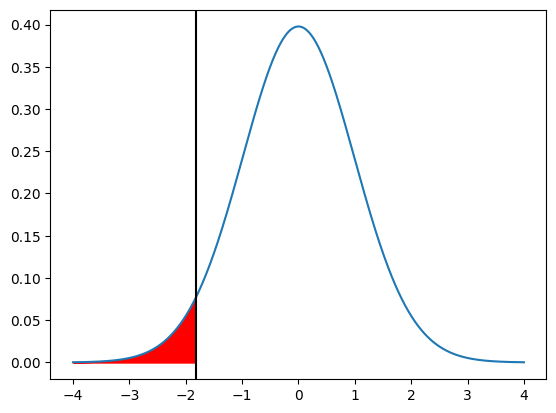

In [37]:
# Illustrate the p-value of the t-test as the area under the t-distribution

x = np.linspace(-4, 4, 1000)

y = stats.t.pdf(x, 80 - 1)

plt.plot(x, y)
plt.fill_between(x, y, where = x < t_stat, color = "red")
plt.axvline(t_stat, color = "black")
plt.show()

In [38]:
print("p-value for the t-statistic:", 1 -  stats.t.cdf(t_stat, 80 - 1))

p-value for the t-statistic: 0.9641660435178603


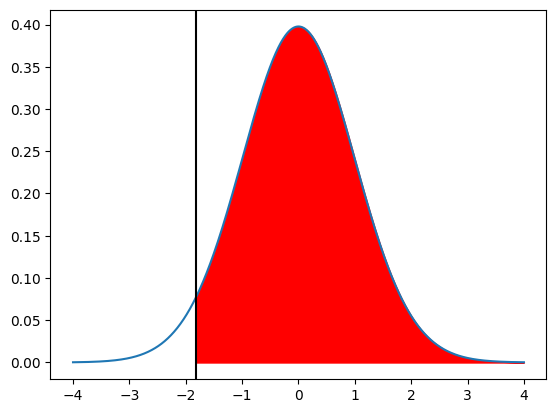

In [39]:
# Illustrate the p-value of the t-test as the area under the t-distribution

x = np.linspace(-4, 4, 1000)

y = stats.t.pdf(x, 80 - 1)

plt.plot(x, y)
plt.fill_between(x, y, where = x > t_stat, color = "red")
plt.axvline(t_stat, color = "black")
plt.show()


In [40]:
# Calculate the p-value for the t-test

print("p-value for the t-test:", 2 * stats.t.cdf(-np.abs(t_stat), 80 - 1))



p-value for the t-test: 0.0716679129642794


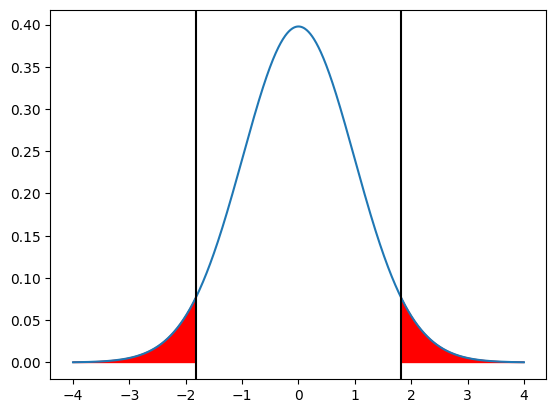

In [41]:
# Illustrate the p-value of the t-test as the area under the t-distribution

x = np.linspace(-4, 4, 1000)

y = stats.t.pdf(x, 80 - 1)

plt.plot(x, y)
plt.fill_between(x, y, where = (x < -np.abs(t_stat)) | (x > np.abs(t_stat)), color = "red")
plt.axvline(t_stat, color = "black")
plt.axvline(-t_stat, color = "black")
plt.show()